# Multi-agent plant analytics — demonstration

Ask a question; the team answers it and you see everything that happened inside.

```
question → orchestrator: intent, split into facts (slots), plan
             ├─ graph_agent   narrows: which tags, which alert window     (Neo4j, Cypher)
             ├─ sql_agent     retrieves exactly that data                 (PostgreSQL, SQL)
             └─ coder_agent   analyses it and draws the figures           (Python sandbox)
         → answer checked by code, with Evidence / Gaps and named figures
```

Architecture explained: `docs/agentic_design/11-agents-architecture-explained.md`.

## Setup

In [1]:
import os, sys
from pathlib import Path

root = Path.cwd()
while not (root / "langgraph.json").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))
os.chdir(root)                      # figures are written under outputs/figures

from mas.config import load_env_file
load_env_file()                     # the whole .env, so LangSmith tracing works too

from mas.notebook import (ask, show_answer, show_plan, show_tool_calls, show_figures,
                          show_data, run_summary, figures_of)

print("gemini key :", "set" if os.getenv("GEMINI_API_KEY") else "MISSING")
print("tracing    :", os.getenv("LANGSMITH_TRACING", "off"))

c:\Users\SriharshaVelicheti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\langchain_core\utils\pydantic.py:41: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


gemini key : set
tracing    : true


## The helpers

| Function | Shows |
|---|---|
| `result = ask(question)` | runs the question, then shows the answer, figures, plan and every tool call; returns the final state |
| `show_answer(result)` | the final answer with the code-written Evidence / Gaps lines |
| `show_figures(result)` | every image the run produced, with its title and file path |
| `show_plan(result)` | the ledger: slots (facts needed), plan steps, status, artifacts |
| `show_tool_calls(result)` | each delegation (brief, status, tokens, time) and every SQL / Cypher / Python call under it |
| `show_data(result, "t4")` | the rows behind a table or record artifact |
| `run_summary(result)` | counts: delegations, tool calls, model calls, tokens, figures |
| `figures_of(result)` | the figure list `[{artifact_id, title, path}]` for your own use |

`ask(question, plan=False, tool_calls=False)` shows only the answer and figures.

## Ask a question

# What is the latest alert on BFP-A? Plot the bearing temperature during that alert window.

## Answer

The latest alert on **Boiler Feed Pump A (BFP-A)** is **ALM-BFPA-0009** on tag `bfpa.bearing_temp_1`. The alert started at **2026-09-03 02:26:00 UTC** and cleared at **2026-09-03 23:59:00 UTC**, reaching a peak temperature of **105.7 degC** at **2026-09-03 23:45:00 UTC**.

---

### Operational & Telemetry Context

- **Tag & Setpoints:** `bfpa.bearing_temp_1` has a normal operating range of **45 degC** to **85 degC**, an **alarm_hi** threshold of **90 degC**, and an **alarm_hihi** threshold of **100 degC**.
- **Alert Peak:** The peak temperature reached **105.7 degC**, exceeding the **alarm_hihi** threshold by **5.7 degC** (105.7 degC − 100 degC = 5.7 degC) and the **alarm_hi** threshold by **15.7 degC** (105.7 degC − 90 degC = 15.7 degC).
- **Average Temperature:** Across the alert window, `bfpa.bearing_temp_1` averaged **95.25 degC**.
- **Maintenance Context:** Work order **WO-BFPA-0001** was carried out on BFP-A to address the high bearing temperature.

---

### Telemetry Plot

- **Figure Title:** *BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)*
- **Description:** Displays the time series of `bfpa.bearing_temp_1` relative to the **alarm_hi** (90 degC) and **alarm_hihi** (100 degC) setpoints, highlighting the active **ALM-BFPA-0009** alert window (02:26:00 to 23:59:00 UTC) and marking the peak temperature of **105.7 degC**.
- **File Path:** `outputs/figures/f6_bfp-a-bearing-temperatures-around-alm-bfpa-0009-03-sep-00-26-04-sep.png`

**Evidence:** f1 ← g1 (s1); f2 ← t3, t4, t5 (s2); f3 ← f6, g1, t4 (s3)

## Figures (1)

**f6 — BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)**  
`outputs\figures\f6_bfp-a-bearing-temperatures-around-alm-bfpa-0009-03-sep-00-26-04-sep.png`

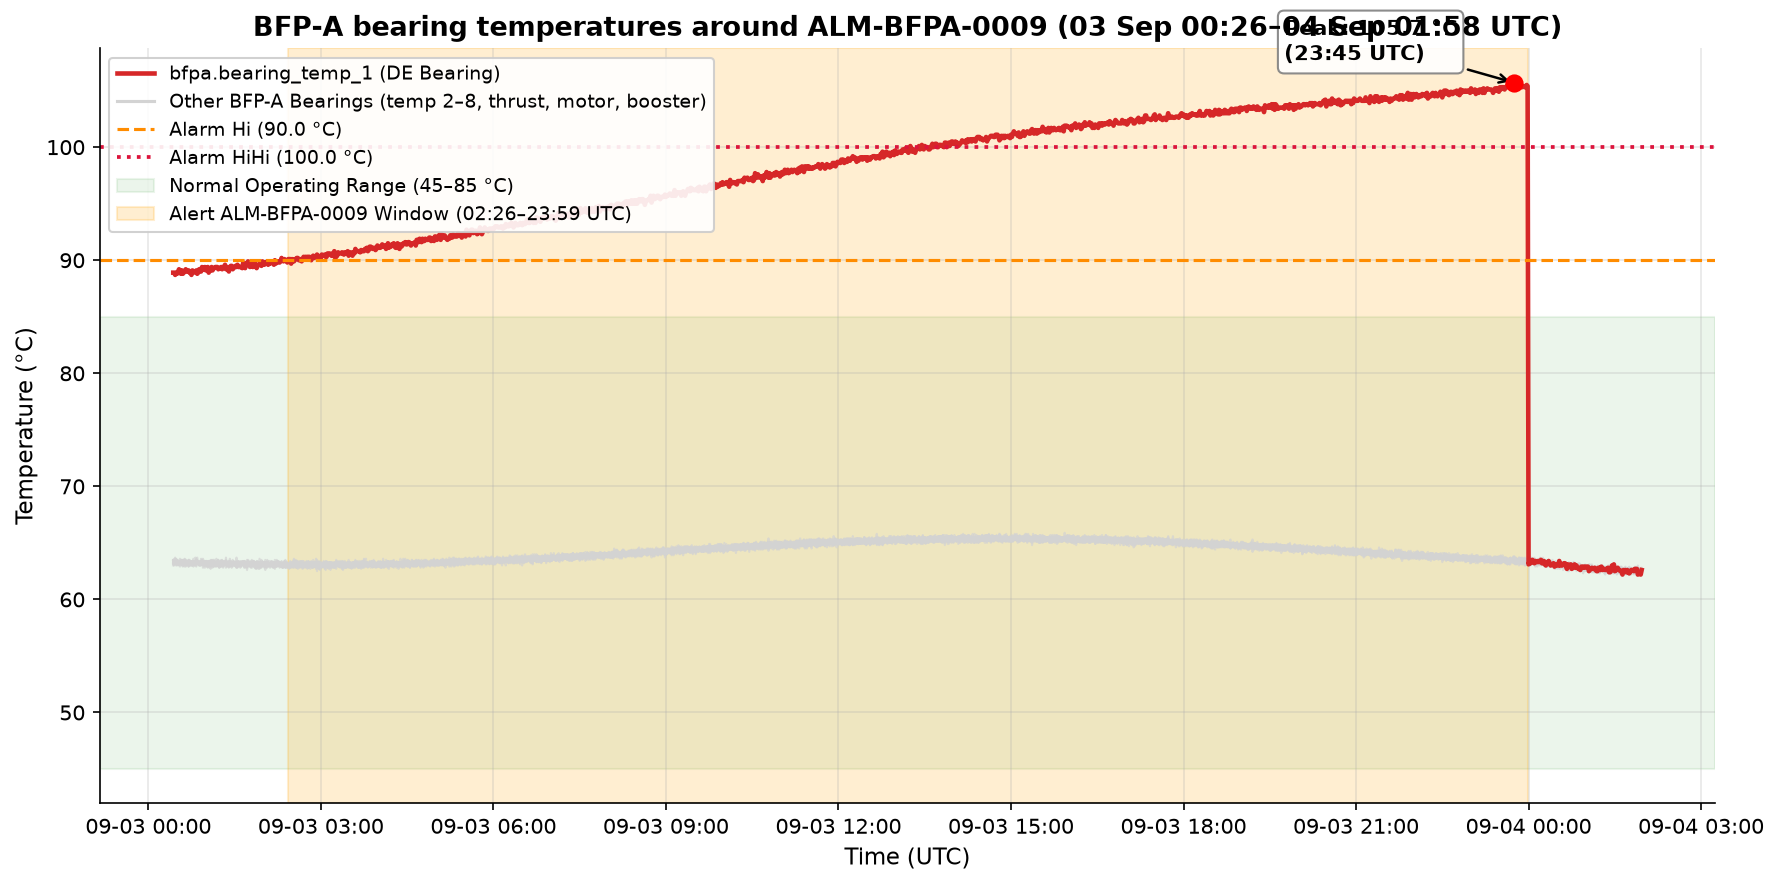

## Plan and ledger

```
## SLOTS (the facts the answer needs; status kept by code)
  f1 [lookup·latest] filled — latest BFP-A alert with telemetry: id, tag, window, peak
      f1 ALM-BFPA-0009 peak_value = 105.7 degC @2026-09-03T02:26:00+00:00 items=['bfpa.bearing_temp_1'] [g1] — Latest BFP-A alert with telemetry is ALM-BFPA-0009 on bfpa.bearing_temp_1 from 2026-09-03T02:26:00Z to 2026-09-03T23:59:00Z with a peak value of 105.7 degC against a hi_hi threshold of 100 degC (alarm_hi: 90 degC, normal: 45-85 degC).
  f2 [measure·series] filled — series of the alert tag and bearing temperature in the alert window, for a plot
      f2 bfpa series items=['bfpa.bearing_temp_1', 'bfpa.bearing_temp_2', 'bfpa.bearing_temp_3', 'bfpa.bearing_temp_4', 'bfpa.bearing_temp_5', 'bfpa.bearing_temp_6', 'bfpa.bearing_temp_7', 'bfpa.bearing_temp_8'] [t3] — Time series of 14 BFP-A bearing temperature sensors over the 25.5-hour alert window around ALM-BFPA-0009.
      f2 bfpa.bearing_temp_1 max = 105.7 degC @2026-09-03T23:45:00+00:00 items=[] [t5] — bfpa.bearing_temp_1 reached a peak temperature of 105.7 °C on 2026-09-03 23:45:00 UTC, exceeding the alarm_hihi threshold (100 °C).
      f2 bfpa.bearing_temp_1 minutes_above = 1289 degC items=[] [t4] — bfpa.bearing_temp_1 spent 1,289 minutes above alarm_hi (90 °C) and 622 minutes above alarm_hihi (100 °C) during the alert window.
      f2 bfpa.bearing_temp_1 avg = 95.25 degC items=[] [t4] — bfpa.bearing_temp_1 averaged 95.25 °C across the entire alert window, compared to an average of ~64.1 °C across all other bearings.
  f3 [derive·figure] filled — plot: bearing temperature series vs alarm_hi/hihi, alert window shaded, peak marked
      f3 bfpa.bearing_temp_1 max = 105.7 degC @2026-09-03T23:45:00+00:00 items=[] [f6] — BFP-A bearing temperature series (bfpa.bearing_temp_1) plotted against Alarm Hi (90 °C) and Alarm HiHi (100 °C) thresholds across 2026-09-03 00:26 to 2026-09-04 01:58 UTC, highlighting the ALM-BFPA-0009 alert window (02:26–23:59 UTC) and peak temperature of 105.7 °C at 23:45 UTC.
      f3 bfpa.bearing_temp_1 minutes_above_alarm_hihi = 622 degC items=[] [t4] — bfpa.bearing_temp_1 spent 622 minutes above the Alarm HiHi threshold (100.0 degC) during the analyzed interval.
      f3 ALM-BFPA-0009 peak_value = 105.7 degC @2026-09-03T23:45:00+00:00 items=[] [g1] — Alert ALM-BFPA-0009 on bfpa.bearing_temp_1 occurred between 2026-09-03 02:26:00 and 2026-09-03 23:59:00 UTC, reaching a peak value of 105.7 degC.

## PLAN
  s1 graph_agent fills ['f1'] done [g1, g2] tags=['bfpa.bearing_temp_1'] alert_ids=['ALM-BFPA-0009'] work_order_ids=['WO-BFPA-0001']
  s2 sql_agent fills ['f2'] done after s1 [t3, t4, t5] tags=['bfpa.bearing_temp_1', 'bfpa.bearing_temp_2', 'bfpa.bearing_temp_3', 'bfpa.bearing_temp_4', 'bfpa.bearing_temp_5', 'bfpa.bearing_temp_6', 'bfpa.bearing_temp_7', 'bfpa.bearing_temp_8', 'bfpa.thrust_bearing_temp_active', 'bfpa.thrust_bearing_temp_inactive', 'bfpa.motor_bearing_temp_de', 'bfpa.motor_bearing_temp_nde', 'bfpa.booster_bearing_temp_1', 'bfpa.booster_bearing_temp_2'] alert_ids=['ALM-BFPA-0009']
  s3 coder_agent fills ['f3'] done after s1,s2 [f6] tags=['bfpa.bearing_temp_1'] alert_ids=['ALM-BFPA-0009'] work_order_ids=['WO-BFPA-0001']

## PROGRESS
  delegations so far: 3; without a newly filled slot in a row: 0/2

## ARTIFACTS
  g1: records, 2 rows
  g2: records, 1 rows
  t3: table, 1533 rows, cols=['ts', 'bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4', 'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7']
  t4: table, 14 rows, cols=['tag_name', 'normal_min', 'normal_max', 'alarm_hi', 'alarm_hihi', 'unit', 'min_val', 'avg_val']
  t5: table, 5 rows, cols=['ts', 'value']
  f6: figure 'BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)' -> outputs\figures\f6_bfp-a-bearing-temperatures-around-alm-bfpa-0009-03-sep-00-26-04-sep.png
```

## Tool calls

**1. set_plan** · `orchestrator` · 0.0 s

### s1 · graph_agent → **done**  
slots f1 · 2 tool calls · 3 model calls · 13,229 tokens · 11.6 s

<details><summary>brief written by code</summary>

```
STEP s1 · graph_agent
SLOT f1 · lookup · latest — latest BFP-A alert with telemetry: id, tag, window, peak
  systems: bfpa (Boiler Feed Pump A)
  the finding must carry: entity, time, value
NOTE: Find the latest alert on BFP-A within telemetry range (or latest overall) with its tag, start/end timestamps, peak value, and setpoints.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `g1`, `g2`

**2. graph_query** · `graph_agent` · 0.4 s · 2 rows · → `g1`

```cypher
MATCH (a:Alert)-[:GENERATED_ON]->(s:System {name: 'bfpa'})
WHERE a.has_telemetry = true
OPTIONAL MATCH (t:Tag {system: 'bfpa', tag_name: a.tag_name})
RETURN a.alert_id AS alert_id,
       a.tag_name AS tag_name,
       a.alert_type AS alert_type,
       a.alert_level AS alert_level,
       a.severity AS severity,
       a.status AS status,
       a.start_ts AS start_ts,
       a.end_ts AS end_ts,
       a.threshold_value AS threshold_value,
       a.peak_value AS peak_value,
       a.has_telemetry AS has_telemetry,
       t.unit AS unit,
       t.normal_min AS normal_min,
       t.normal_max AS normal_max,
       t.alarm_hi AS alarm_hi,
       t.alarm_hihi AS alarm_hihi
ORDER BY a.start_ts DESC, a.alert_id DESC
LIMIT 5
```

**3. graph_query** · `graph_agent` · 0.2 s · 1 rows · → `g2`

```cypher
MATCH (m:MaintenanceLog)-[:PERFORMED_ON]->(s:System {name: 'bfpa'})
WHERE m.related_alert_id = 'ALM-BFPA-0009' OR m.start_ts >= datetime('2026-09-03T00:00:00Z')
RETURN m.work_order_id AS work_order_id,
       m.maintenance_type AS maintenance_type,
       m.maintenance_class AS maintenance_class,
       m.failure_mode AS failure_mode,
       m.start_ts AS start_ts,
       m.end_ts AS end_ts,
       m.downtime_hours AS downtime_hours,
       m.total_cost AS total_cost,
       m.related_alert_id AS related_alert_id
```

### s2 · sql_agent → **done**  
slots f2 · 4 tool calls · 5 model calls · 37,078 tokens · 19.3 s

<details><summary>brief written by code</summary>

```
STEP s2 · sql_agent
SLOT f2 · measure · series — series of the alert tag and bearing temperature in the alert window, for a plot
  systems: bfpa (Boiler Feed Pump A)
  tags (14; 1 given; bearing temperature@bfpa: 14 via glossary) — the slot is about these; add related tags only if they sharpen the answer, and say so:
    [degC, normal 45..85, alarm_hi 90, alarm_hihi 100] bfpa.bearing_temp_1, bfpa.bearing_temp_2, bfpa.bearing_temp_3, bfpa.bearing_temp_4, bfpa.bearing_temp_5, bfpa.bearing_temp_6, bfpa.bearing_temp_7, bfpa.bearing_temp_8, bfpa.thrust_bearing_temp_active, bfpa.thrust_bearing_temp_inactive, bfpa.motor_bearing_temp_de, bfpa.motor_bearing_temp_nde, bfpa.booster_bearing_temp_1, bfpa.booster_bearing_temp_2
  window: [2026-09-03T00:26:00+00:00, 2026-09-04T01:59:00+00:00)  ALM-BFPA-0009 ± 2 h — resolved in code; use verbatim
  the finding must carry: entity
INPUTS:
  g1: records, 2 rows
  g2: records, 1 rows
NOTE: Fetch bearing temperature time series for BFP-A around the alert window of ALM-BFPA-0009.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `t3`, `t4`, `t5`

code checks: f2: unit 'min' for bfpa.bearing_temp_1 corrected to catalog unit 'degC'

**4. sql_query** · `sql_agent` · 0.1 s · 1,533 rows · → `t3`

```sql
SELECT ts, bearing_temp_1, bearing_temp_2, bearing_temp_3, bearing_temp_4, bearing_temp_5, bearing_temp_6, bearing_temp_7, bearing_temp_8, thrust_bearing_temp_active, thrust_bearing_temp_inactive, motor_bearing_temp_de, motor_bearing_temp_nde, booster_bearing_temp_1, booster_bearing_temp_2 FROM bfpa WHERE ts >= '2026-09-03T00:26:00+00:00' AND ts < '2026-09-04T01:59:00+00:00' ORDER BY ts ASC LIMIT 200000
```

**5. sql_query** · `sql_agent` · 0.0 s

> ❌ column reference &quot;tag_name&quot; is ambiguous
LINE 1: SELECT tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.a...
               ^

```sql
SELECT 
    tag_name,
    c.normal_min,
    c.normal_max,
    c.alarm_hi,
    c.alarm_hihi,
    c.unit,
    min(value) as min_val,
    avg(value) as avg_val,
    max(value) as max_val,
    count(*) FILTER (WHERE value > c.alarm_hi) as minutes_above_alarm_hi,
    count(*) FILTER (WHERE value > c.alarm_hihi) as minutes_above_alarm_hihi
FROM bfpa_long l
JOIN sensor_catalog c ON c.system = 'bfpa' AND c.tag_name = l.tag_name
WHERE l.ts >= '2026-09-03T00:26:00+00:00' AND l.ts < '2026-09-04T01:59:00+00:00'
  AND l.tag_name IN (
    'bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4',
    'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8',
    'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive',
    'motor_bearing_temp_de', 'motor_bearing_temp_nde',
    'booster_bearing_temp_1', 'booster_bearing_temp_2'
  )
GROUP BY tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit
ORDER BY max_val DESC;
```

**6. sql_query** · `sql_agent` · 0.1 s · 14 rows · → `t4`

```sql
SELECT l.tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit, MIN(value) AS min_val, AVG(value) AS avg_val, MAX(value) AS max_val, COUNT(*) FILTER(WHERE value > c.alarm_hi) AS minutes_above_alarm_hi, COUNT(*) FILTER(WHERE value > c.alarm_hihi) AS minutes_above_alarm_hihi FROM bfpa_long AS l JOIN sensor_catalog AS c ON c.system = 'bfpa' AND c.tag_name = l.tag_name WHERE l.ts >= '2026-09-03T00:26:00+00:00' AND l.ts < '2026-09-04T01:59:00+00:00' AND l.tag_name IN ('bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4', 'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8', 'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive', 'motor_bearing_temp_de', 'motor_bearing_temp_nde', 'booster_bearing_temp_1', 'booster_bearing_temp_2') GROUP BY l.tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit ORDER BY max_val DESC LIMIT 200000
```

**7. sql_query** · `sql_agent` · 0.1 s · 5 rows · → `t5`

```sql
SELECT ts, value FROM bfpa_long WHERE tag_name = 'bearing_temp_1' AND ts >= '2026-09-03T00:26:00+00:00' AND ts < '2026-09-04T01:59:00+00:00' ORDER BY value DESC, ts ASC LIMIT 5
```

### s3 · coder_agent → **done**  
slots f3 · 4 tool calls · 5 model calls · 31,699 tokens · 24.2 s

<details><summary>brief written by code</summary>

```
STEP s3 · coder_agent
SLOT f3 · derive · figure — plot: bearing temperature series vs alarm_hi/hihi, alert window shaded, peak marked
  systems: bfpa (Boiler Feed Pump A)
  tags (1; 1 given; bearing temperature@bfpa: 1 via glossary) — the slot is about these; use their units for axes and their setpoints for threshold lines:
    [degC, normal 45..85, alarm_hi 90, alarm_hihi 100] bfpa.bearing_temp_1
  the finding must carry: figure
INPUTS:
  g1: records, 2 rows
  g2: records, 1 rows
  t3: table, 1533 rows, cols=['ts', 'bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4', 'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8', 'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive', 'motor_bearing_temp_de']
  t4: table, 14 rows, cols=['tag_name', 'normal_min', 'normal_max', 'alarm_hi', 'alarm_hihi', 'unit', 'min_val', 'avg_val', 'max_val', 'minutes_above_alarm_hi', 'minutes_above_alarm_hihi']
  t5: table, 5 rows, cols=['ts', 'value']
NOTE: Plot bearing temperatures with alarm lines, shaded alert window, and peak labeled.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `f6`

code checks: f3: unit 'min' for bfpa.bearing_temp_1 corrected to catalog unit 'degC'

**8. python_analysis** · `coder_agent` · 1.2 s

```python
print("g1:", dfs['g1'])
print("g2:", dfs['g2'])
print("t4:", dfs['t4'])
print("t5:", dfs['t5'])
print("t3 head:", dfs['t3'].head(2))
print("t3 info:", dfs['t3'].info())
```

**9. python_analysis** · `coder_agent` · 0.0 s

```python
for col in dfs['g1'].columns:
    print(f"g1 {col}: {dfs['g1'][col].values}")
for col in dfs['g2'].columns:
    print(f"g2 {col}: {dfs['g2'][col].values}")

print("\nt4 full:")
print(dfs['t4'])

print("\nt3 range:")
print("ts min:", dfs['t3']['ts'].min(), "ts max:", dfs['t3']['ts'].max())
print("bearing_temp_1 min:", dfs['t3']['bearing_temp_1'].min(), "max:", dfs['t3']['bearing_temp_1'].max(), "avg:", dfs['t3']['bearing_temp_1'].mean())

# Find peak of bearing_temp_1
peak_idx = dfs['t3']['bearing_temp_1'].idxmax()
peak_row = dfs['t3'].loc[peak_idx]
print(f"Peak bearing_temp_1: {peak_row['bearing_temp_1']} at {peak_row['ts']}")
```

**10. python_analysis** · `coder_agent` · 0.5 s · figures `f6`

```python
import matplotlib.dates as mdates

df_telemetry = dfs['t3'].copy()
df_telemetry['ts'] = pd.to_datetime(df_telemetry['ts'], utc=True)

# Sort by ts
df_telemetry = df_telemetry.sort_values('ts')

# Alert window
alm_start = pd.to_datetime('2026-09-03T02:26:00+00:00', utc=True)
alm_end = pd.to_datetime('2026-09-03T23:59:00+00:00', utc=True)

# Peak info
peak_val = 105.7
peak_time = pd.to_datetime('2026-09-03 23:45:00+00:00', utc=True)

plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1)

# Plot other bearing temperatures in light grey / muted colors
bearing_cols = [c for c in df_telemetry.columns if c != 'ts' and c != 'bearing_temp_1']
for col in bearing_cols:
    ax.plot(df_telemetry['ts'], df_telemetry[col], color='lightgray', linewidth=1.0, alpha=0.7, label='_nolegend_')

# Plot bearing_temp_1 in distinct prominent color
ax.plot(df_telemetry['ts'], df_telemetry['bearing_temp_1'], color='#d62728', linewidth=2.2, label='bfpa.bearing_temp_1 (DE Bearing)')

# Plot other bearing temps summary in legend by adding a proxy artist if needed, or simply label bearing_temp_1
ax.plot([], [], color='lightgray', linewidth=1.5, label='Other BFP-A Bearings (temp 2–8, thrust, motor, booster)')

# Alarm lines
ax.axhline(90, color='darkorange', linestyle='--', linewidth=1.5, label='Alarm Hi (90.0 °C)')
ax.axhline(100, color='crimson', linestyle=':', linewidth=1.8, label='Alarm HiHi (100.0 °C)')

# Normal range band
ax.axhspan(45, 85, color='green', alpha=0.08, label='Normal Operating Range (45–85 °C)')

# Event window shading
ax.axvspan(alm_start, alm_end, color='orange', alpha=0.18, label='Alert ALM-BFPA-0009 Window (02:26–23:59 UTC)')

# Mark Peak
ax.scatter([peak_time], [peak_val], color='red', s=60, zorder=5)
ax.annotate(f'Peak: {peak_val:.1f} °C\n(23:45 UTC)',
            xy=(peak_time, peak_val),
            xytext=(peak_time - pd.Timedelta(hours=4), peak_val + 2.0),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
            fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set_title("BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)", fontsize=13, fontweight='bold')
ax.set_xlabel("Time (UTC)", fontsize=11)
ax.set_ylabel("Temperature (°C)", fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()
```

**11. python_analysis** · `coder_agent` · 0.0 s

```python
print("Minutes above alarm_hihi:", dfs['t4'][dfs['t4']['tag_name']=='bearing_temp_1']['minutes_above_alarm_hihi'].values[0])
print("Minutes above alarm_hi:", dfs['t4'][dfs['t4']['tag_name']=='bearing_temp_1']['minutes_above_alarm_hi'].values[0])
print("Mean bearing_temp_1:", dfs['t3']['bearing_temp_1'].mean())
```

_81 s · 3 delegations · 11 tool calls (1 failed) · 18 model calls · 127,208 tokens · 1 figures_

In [2]:
QUESTION = "What is the latest alert on BFP-A? Plot the bearing temperature during that alert window."

result = ask(QUESTION)

## Look again at any part

In [3]:
show_tool_calls(result)

## Tool calls

**1. set_plan** · `orchestrator` · 0.0 s

### s1 · graph_agent → **done**  
slots f1 · 2 tool calls · 3 model calls · 13,229 tokens · 11.6 s

<details><summary>brief written by code</summary>

```
STEP s1 · graph_agent
SLOT f1 · lookup · latest — latest BFP-A alert with telemetry: id, tag, window, peak
  systems: bfpa (Boiler Feed Pump A)
  the finding must carry: entity, time, value
NOTE: Find the latest alert on BFP-A within telemetry range (or latest overall) with its tag, start/end timestamps, peak value, and setpoints.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `g1`, `g2`

**2. graph_query** · `graph_agent` · 0.4 s · 2 rows · → `g1`

```cypher
MATCH (a:Alert)-[:GENERATED_ON]->(s:System {name: 'bfpa'})
WHERE a.has_telemetry = true
OPTIONAL MATCH (t:Tag {system: 'bfpa', tag_name: a.tag_name})
RETURN a.alert_id AS alert_id,
       a.tag_name AS tag_name,
       a.alert_type AS alert_type,
       a.alert_level AS alert_level,
       a.severity AS severity,
       a.status AS status,
       a.start_ts AS start_ts,
       a.end_ts AS end_ts,
       a.threshold_value AS threshold_value,
       a.peak_value AS peak_value,
       a.has_telemetry AS has_telemetry,
       t.unit AS unit,
       t.normal_min AS normal_min,
       t.normal_max AS normal_max,
       t.alarm_hi AS alarm_hi,
       t.alarm_hihi AS alarm_hihi
ORDER BY a.start_ts DESC, a.alert_id DESC
LIMIT 5
```

**3. graph_query** · `graph_agent` · 0.2 s · 1 rows · → `g2`

```cypher
MATCH (m:MaintenanceLog)-[:PERFORMED_ON]->(s:System {name: 'bfpa'})
WHERE m.related_alert_id = 'ALM-BFPA-0009' OR m.start_ts >= datetime('2026-09-03T00:00:00Z')
RETURN m.work_order_id AS work_order_id,
       m.maintenance_type AS maintenance_type,
       m.maintenance_class AS maintenance_class,
       m.failure_mode AS failure_mode,
       m.start_ts AS start_ts,
       m.end_ts AS end_ts,
       m.downtime_hours AS downtime_hours,
       m.total_cost AS total_cost,
       m.related_alert_id AS related_alert_id
```

### s2 · sql_agent → **done**  
slots f2 · 4 tool calls · 5 model calls · 37,078 tokens · 19.3 s

<details><summary>brief written by code</summary>

```
STEP s2 · sql_agent
SLOT f2 · measure · series — series of the alert tag and bearing temperature in the alert window, for a plot
  systems: bfpa (Boiler Feed Pump A)
  tags (14; 1 given; bearing temperature@bfpa: 14 via glossary) — the slot is about these; add related tags only if they sharpen the answer, and say so:
    [degC, normal 45..85, alarm_hi 90, alarm_hihi 100] bfpa.bearing_temp_1, bfpa.bearing_temp_2, bfpa.bearing_temp_3, bfpa.bearing_temp_4, bfpa.bearing_temp_5, bfpa.bearing_temp_6, bfpa.bearing_temp_7, bfpa.bearing_temp_8, bfpa.thrust_bearing_temp_active, bfpa.thrust_bearing_temp_inactive, bfpa.motor_bearing_temp_de, bfpa.motor_bearing_temp_nde, bfpa.booster_bearing_temp_1, bfpa.booster_bearing_temp_2
  window: [2026-09-03T00:26:00+00:00, 2026-09-04T01:59:00+00:00)  ALM-BFPA-0009 ± 2 h — resolved in code; use verbatim
  the finding must carry: entity
INPUTS:
  g1: records, 2 rows
  g2: records, 1 rows
NOTE: Fetch bearing temperature time series for BFP-A around the alert window of ALM-BFPA-0009.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `t3`, `t4`, `t5`

code checks: f2: unit 'min' for bfpa.bearing_temp_1 corrected to catalog unit 'degC'

**4. sql_query** · `sql_agent` · 0.1 s · 1,533 rows · → `t3`

```sql
SELECT ts, bearing_temp_1, bearing_temp_2, bearing_temp_3, bearing_temp_4, bearing_temp_5, bearing_temp_6, bearing_temp_7, bearing_temp_8, thrust_bearing_temp_active, thrust_bearing_temp_inactive, motor_bearing_temp_de, motor_bearing_temp_nde, booster_bearing_temp_1, booster_bearing_temp_2 FROM bfpa WHERE ts >= '2026-09-03T00:26:00+00:00' AND ts < '2026-09-04T01:59:00+00:00' ORDER BY ts ASC LIMIT 200000
```

**5. sql_query** · `sql_agent` · 0.0 s

> ❌ column reference &quot;tag_name&quot; is ambiguous
LINE 1: SELECT tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.a...
               ^

```sql
SELECT 
    tag_name,
    c.normal_min,
    c.normal_max,
    c.alarm_hi,
    c.alarm_hihi,
    c.unit,
    min(value) as min_val,
    avg(value) as avg_val,
    max(value) as max_val,
    count(*) FILTER (WHERE value > c.alarm_hi) as minutes_above_alarm_hi,
    count(*) FILTER (WHERE value > c.alarm_hihi) as minutes_above_alarm_hihi
FROM bfpa_long l
JOIN sensor_catalog c ON c.system = 'bfpa' AND c.tag_name = l.tag_name
WHERE l.ts >= '2026-09-03T00:26:00+00:00' AND l.ts < '2026-09-04T01:59:00+00:00'
  AND l.tag_name IN (
    'bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4',
    'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8',
    'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive',
    'motor_bearing_temp_de', 'motor_bearing_temp_nde',
    'booster_bearing_temp_1', 'booster_bearing_temp_2'
  )
GROUP BY tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit
ORDER BY max_val DESC;
```

**6. sql_query** · `sql_agent` · 0.1 s · 14 rows · → `t4`

```sql
SELECT l.tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit, MIN(value) AS min_val, AVG(value) AS avg_val, MAX(value) AS max_val, COUNT(*) FILTER(WHERE value > c.alarm_hi) AS minutes_above_alarm_hi, COUNT(*) FILTER(WHERE value > c.alarm_hihi) AS minutes_above_alarm_hihi FROM bfpa_long AS l JOIN sensor_catalog AS c ON c.system = 'bfpa' AND c.tag_name = l.tag_name WHERE l.ts >= '2026-09-03T00:26:00+00:00' AND l.ts < '2026-09-04T01:59:00+00:00' AND l.tag_name IN ('bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4', 'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8', 'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive', 'motor_bearing_temp_de', 'motor_bearing_temp_nde', 'booster_bearing_temp_1', 'booster_bearing_temp_2') GROUP BY l.tag_name, c.normal_min, c.normal_max, c.alarm_hi, c.alarm_hihi, c.unit ORDER BY max_val DESC LIMIT 200000
```

**7. sql_query** · `sql_agent` · 0.1 s · 5 rows · → `t5`

```sql
SELECT ts, value FROM bfpa_long WHERE tag_name = 'bearing_temp_1' AND ts >= '2026-09-03T00:26:00+00:00' AND ts < '2026-09-04T01:59:00+00:00' ORDER BY value DESC, ts ASC LIMIT 5
```

### s3 · coder_agent → **done**  
slots f3 · 4 tool calls · 5 model calls · 31,699 tokens · 24.2 s

<details><summary>brief written by code</summary>

```
STEP s3 · coder_agent
SLOT f3 · derive · figure — plot: bearing temperature series vs alarm_hi/hihi, alert window shaded, peak marked
  systems: bfpa (Boiler Feed Pump A)
  tags (1; 1 given; bearing temperature@bfpa: 1 via glossary) — the slot is about these; use their units for axes and their setpoints for threshold lines:
    [degC, normal 45..85, alarm_hi 90, alarm_hihi 100] bfpa.bearing_temp_1
  the finding must carry: figure
INPUTS:
  g1: records, 2 rows
  g2: records, 1 rows
  t3: table, 1533 rows, cols=['ts', 'bearing_temp_1', 'bearing_temp_2', 'bearing_temp_3', 'bearing_temp_4', 'bearing_temp_5', 'bearing_temp_6', 'bearing_temp_7', 'bearing_temp_8', 'thrust_bearing_temp_active', 'thrust_bearing_temp_inactive', 'motor_bearing_temp_de']
  t4: table, 14 rows, cols=['tag_name', 'normal_min', 'normal_max', 'alarm_hi', 'alarm_hihi', 'unit', 'min_val', 'avg_val', 'max_val', 'minutes_above_alarm_hi', 'minutes_above_alarm_hihi']
  t5: table, 5 rows, cols=['ts', 'value']
NOTE: Plot bearing temperatures with alarm lines, shaded alert window, and peak labeled.
REPORT: at least one finding per slot above, slot_id set. Numbers in value, unit in unit, event times in time, the tag / alert / work order in entity, list or rank items in items ([] when none were found). Put what else you noticed about these slots in the answer.
```

</details>

artifacts created: `f6`

code checks: f3: unit 'min' for bfpa.bearing_temp_1 corrected to catalog unit 'degC'

**8. python_analysis** · `coder_agent` · 1.2 s

```python
print("g1:", dfs['g1'])
print("g2:", dfs['g2'])
print("t4:", dfs['t4'])
print("t5:", dfs['t5'])
print("t3 head:", dfs['t3'].head(2))
print("t3 info:", dfs['t3'].info())
```

**9. python_analysis** · `coder_agent` · 0.0 s

```python
for col in dfs['g1'].columns:
    print(f"g1 {col}: {dfs['g1'][col].values}")
for col in dfs['g2'].columns:
    print(f"g2 {col}: {dfs['g2'][col].values}")

print("\nt4 full:")
print(dfs['t4'])

print("\nt3 range:")
print("ts min:", dfs['t3']['ts'].min(), "ts max:", dfs['t3']['ts'].max())
print("bearing_temp_1 min:", dfs['t3']['bearing_temp_1'].min(), "max:", dfs['t3']['bearing_temp_1'].max(), "avg:", dfs['t3']['bearing_temp_1'].mean())

# Find peak of bearing_temp_1
peak_idx = dfs['t3']['bearing_temp_1'].idxmax()
peak_row = dfs['t3'].loc[peak_idx]
print(f"Peak bearing_temp_1: {peak_row['bearing_temp_1']} at {peak_row['ts']}")
```

**10. python_analysis** · `coder_agent` · 0.5 s · figures `f6`

```python
import matplotlib.dates as mdates

df_telemetry = dfs['t3'].copy()
df_telemetry['ts'] = pd.to_datetime(df_telemetry['ts'], utc=True)

# Sort by ts
df_telemetry = df_telemetry.sort_values('ts')

# Alert window
alm_start = pd.to_datetime('2026-09-03T02:26:00+00:00', utc=True)
alm_end = pd.to_datetime('2026-09-03T23:59:00+00:00', utc=True)

# Peak info
peak_val = 105.7
peak_time = pd.to_datetime('2026-09-03 23:45:00+00:00', utc=True)

plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1)

# Plot other bearing temperatures in light grey / muted colors
bearing_cols = [c for c in df_telemetry.columns if c != 'ts' and c != 'bearing_temp_1']
for col in bearing_cols:
    ax.plot(df_telemetry['ts'], df_telemetry[col], color='lightgray', linewidth=1.0, alpha=0.7, label='_nolegend_')

# Plot bearing_temp_1 in distinct prominent color
ax.plot(df_telemetry['ts'], df_telemetry['bearing_temp_1'], color='#d62728', linewidth=2.2, label='bfpa.bearing_temp_1 (DE Bearing)')

# Plot other bearing temps summary in legend by adding a proxy artist if needed, or simply label bearing_temp_1
ax.plot([], [], color='lightgray', linewidth=1.5, label='Other BFP-A Bearings (temp 2–8, thrust, motor, booster)')

# Alarm lines
ax.axhline(90, color='darkorange', linestyle='--', linewidth=1.5, label='Alarm Hi (90.0 °C)')
ax.axhline(100, color='crimson', linestyle=':', linewidth=1.8, label='Alarm HiHi (100.0 °C)')

# Normal range band
ax.axhspan(45, 85, color='green', alpha=0.08, label='Normal Operating Range (45–85 °C)')

# Event window shading
ax.axvspan(alm_start, alm_end, color='orange', alpha=0.18, label='Alert ALM-BFPA-0009 Window (02:26–23:59 UTC)')

# Mark Peak
ax.scatter([peak_time], [peak_val], color='red', s=60, zorder=5)
ax.annotate(f'Peak: {peak_val:.1f} °C\n(23:45 UTC)',
            xy=(peak_time, peak_val),
            xytext=(peak_time - pd.Timedelta(hours=4), peak_val + 2.0),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
            fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set_title("BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)", fontsize=13, fontweight='bold')
ax.set_xlabel("Time (UTC)", fontsize=11)
ax.set_ylabel("Temperature (°C)", fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()
```

**11. python_analysis** · `coder_agent` · 0.0 s

```python
print("Minutes above alarm_hihi:", dfs['t4'][dfs['t4']['tag_name']=='bearing_temp_1']['minutes_above_alarm_hihi'].values[0])
print("Minutes above alarm_hi:", dfs['t4'][dfs['t4']['tag_name']=='bearing_temp_1']['minutes_above_alarm_hi'].values[0])
print("Mean bearing_temp_1:", dfs['t3']['bearing_temp_1'].mean())
```

## Figures (1)

**f6 — BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)**  
`outputs\figures\f6_bfp-a-bearing-temperatures-around-alm-bfpa-0009-03-sep-00-26-04-sep.png`

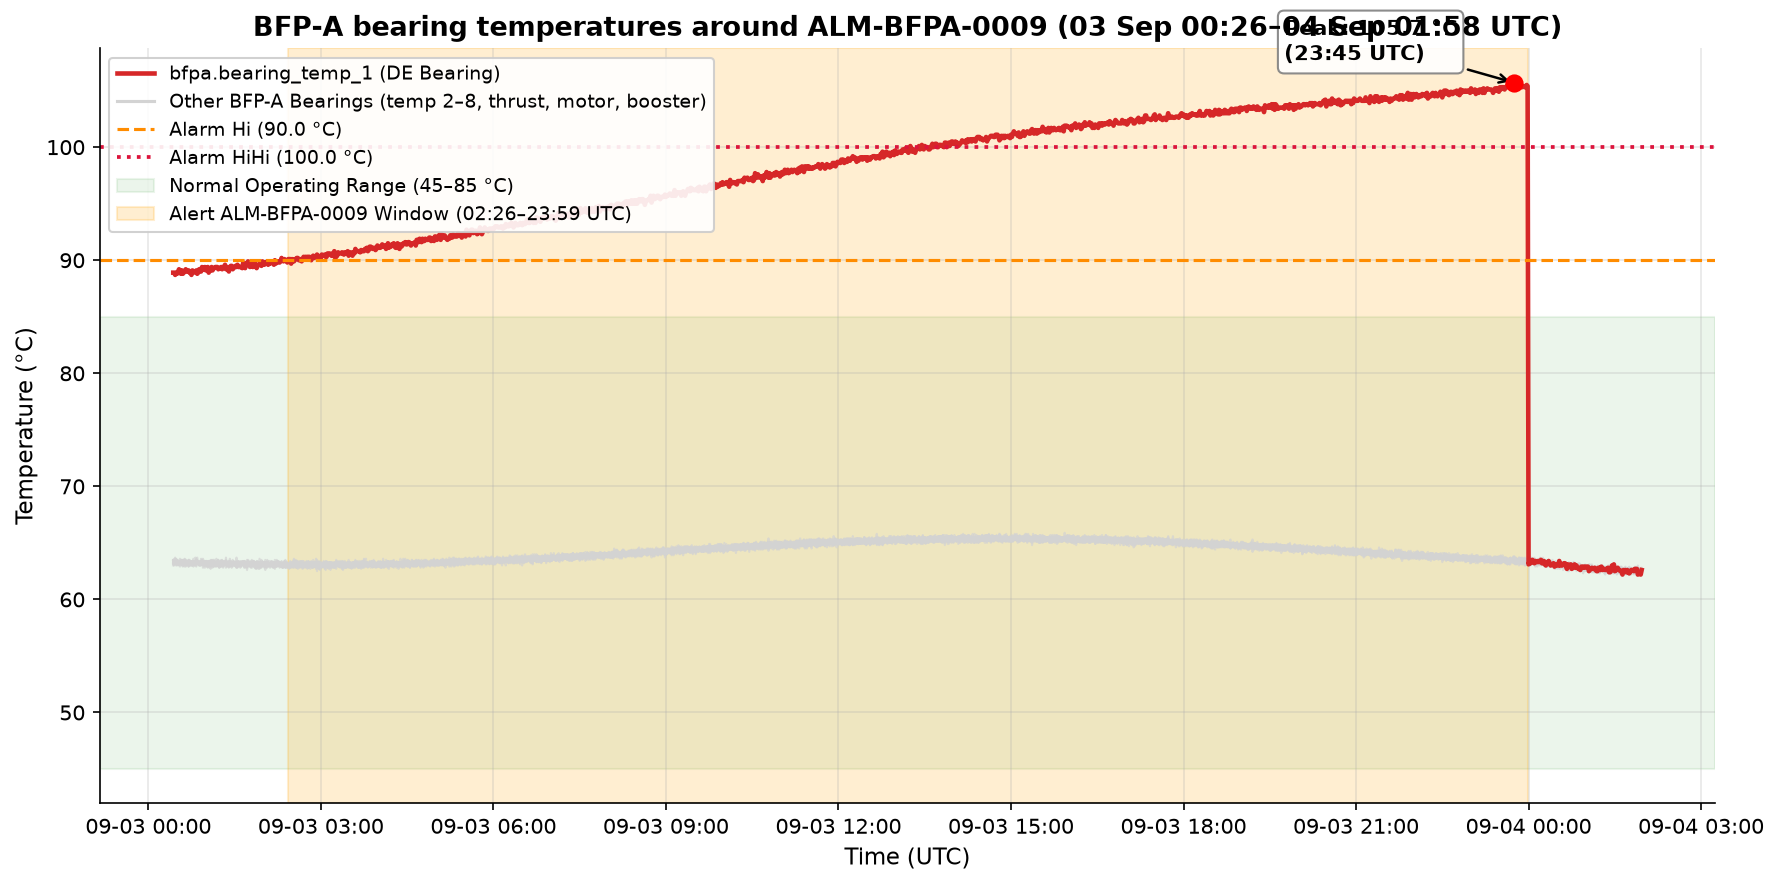

[{'artifact_id': 'f6',
  'title': 'BFP-A bearing temperatures around ALM-BFPA-0009 (03 Sep 00:26–04 Sep 01:58 UTC)',
  'path': 'outputs\\figures\\f6_bfp-a-bearing-temperatures-around-alm-bfpa-0009-03-sep-00-26-04-sep.png'}]

In [4]:
show_figures(result)

In [5]:
run_summary(result)

{'delegations': 3,
 'rejected_delegations': 0,
 'tool_calls': 11,
 'failed_tool_calls': 1,
 'orchestrator_model_calls': 5,
 'specialist_model_calls': 13,
 'input_tokens': 114321,
 'output_tokens': 12887,
 'figures': 1,
 'specialist_seconds': 55.2}

In [ ]:
# The rows behind any table or record artifact listed in the plan / tool calls:
data_ids = [k for k, d in result["blackboard"].items() if d.get("kind") in ("table", "records")]
print(data_ids)
if data_ids:
    show_data(result, data_ids[0])

## Your question

Some to try:
- *Why is the turbine vibrating?* — graph narrows the tags → sql pulls their series → coder analyses and plots
- *Which BFP ran hotter over the last 7 days?*
- *How many minutes was any BFP-A bearing above alarm_hi yesterday?*
- *What did maintenance on the turbine cost, and which part was used most?*
- *Cluster BFP-A's operating regions by load, efficiency and vibration and plot them.*

In [ ]:
my_result = ask("Why is the turbine vibrating?")